# WiperTrace — pattern recognition on the collected runs

**Part 1** turns the 72 harness runs into labelled feature tables and trains
interpretable classifiers that answer two questions:

| Task | Unit | Question | Evidence used |
|---|---|---|---|
| **A** | one wiped file (MFT record) | *Which tool removed this file?* | `$UsnJrnl:$J` records for that file |
| **B** | one run (whole volume) | *Which tool ran on this volume?* | journal summary ± Prefetch (ablation) |

**Part 2** (from section 9) adds `$MFT`, `$LogFile` and Amcache, and an ablation across all evidence types.

Everything is parsed in pure Python, so it runs on Colab's Linux machines without
the Windows-only Eric Zimmerman tools.

**Before you start:** upload the results zip (the one containing the 72
`00NN_<tool>_<mode>_<shutdown>_rN` folders: 0001-0060 from October,
0061-0072 CCleaner and BCWipe from 6 Nov) to Google Drive at
`MyDrive/WiperTrace/final.zip`, or change `DATA_ZIP` below.

## 1. Setup

In [1]:
import os, re, sys, zipfile
from pathlib import Path
from google.colab import drive

#DATASET_PATH = 'final.zip'
IN_COLAB = "google.colab" in sys.modules

# Where the results zip lives (Colab) and where it is unpacked.
DATA_ZIP = Path("/content/drive/MyDrive/Colab Notebooks/DF/final.zip")
RUNS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/DF/runs")
OUT_DIR  = Path("/content/drive/MyDrive/Colab Notebooks/DF/ml_out")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not DATA_ZIP.exists():
        raise FileNotFoundError(f"Upload the results zip to {DATA_ZIP} "
                                "(or edit DATA_ZIP) and re-run this cell.")
    # RUNS_DIR lives on Drive, so it survives between sessions. Extract only
    # the run folders that are in the zip but not yet unpacked - otherwise a
    # new zip with extra runs (e.g. 0061-0072) would be silently ignored.
    RUNS_DIR.mkdir(parents=True, exist_ok=True)
    run_name = lambda path: next((p for p in path.split("/") if re.match(r"\d{4}_", p)), None)
    have = {p.parent.name for p in RUNS_DIR.rglob("manifest.json")}
    with zipfile.ZipFile(DATA_ZIP) as z:
        members = [m for m in z.namelist() if run_name(m) and run_name(m) not in have]
        if members:
            print(f"unpacking {len({run_name(m) for m in members})} new run folders ...")
            z.extractall(RUNS_DIR, members=members)
else:
    # Running locally (Jupyter / VS Code): point at an unpacked runs folder.
    RUNS_DIR = Path(os.environ.get("WIPERTRACE_RUNS", "runs"))
    OUT_DIR  = Path(os.environ.get("WIPERTRACE_OUT", "ml_out"))

OUT_DIR.mkdir(parents=True, exist_ok=True)
run_dirs = sorted({p.parent.name: p.parent for p in RUNS_DIR.rglob("manifest.json")}.values(),
                  key=lambda p: p.name)
print(f"{len(run_dirs)} run folders under {RUNS_DIR}")

Mounted at /content/drive
72 run folders under /content/drive/MyDrive/Colab Notebooks/DF/runs


In [2]:
import gzip, json, math, re, struct
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

pd.set_option("display.width", 160)
RNG = 0

## 2. Parse the USN change journal (`$J`)

Each `evidence/$J.gz` is the raw `$UsnJrnl:$J` stream carved by the harness.
It is mostly zero padding (the journal is sparse) with `USN_RECORD_V2`
structures in between. Layout of one record (all little-endian):

| offset | size | field |
|---|---|---|
| 0 | 4 | RecordLength |
| 4 | 2 | MajorVersion (2) |
| 8 | 8 | FileReferenceNumber (low 48 bits = MFT record, high 16 = sequence) |
| 16 | 8 | ParentFileReferenceNumber |
| 24 | 8 | Usn |
| 32 | 8 | TimeStamp (FILETIME, UTC) |
| 40 | 4 | Reason flags |
| 52 | 4 | FileAttributes |
| 56 | 2 | FileNameLength · 58: FileNameOffset |

In [3]:
REASONS = {
    "DATA_OVERWRITE": 0x1, "DATA_EXTEND": 0x2, "DATA_TRUNCATION": 0x4,
    "NAMED_DATA_OVERWRITE": 0x10, "NAMED_DATA_EXTEND": 0x20, "NAMED_DATA_TRUNCATION": 0x40,
    "FILE_CREATE": 0x100, "FILE_DELETE": 0x200, "EA_CHANGE": 0x400,
    "SECURITY_CHANGE": 0x800, "RENAME_OLD_NAME": 0x1000, "RENAME_NEW_NAME": 0x2000,
    "INDEXABLE_CHANGE": 0x4000, "BASIC_INFO_CHANGE": 0x8000, "HARD_LINK_CHANGE": 0x10000,
    "COMPRESSION_CHANGE": 0x20000, "ENCRYPTION_CHANGE": 0x40000, "OBJECT_ID_CHANGE": 0x80000,
    "REPARSE_POINT_CHANGE": 0x100000, "STREAM_CHANGE": 0x200000, "CLOSE": 0x80000000,
}
# FILETIME counts 100-ns ticks since 1601-01-01. Shift to the Unix epoch BEFORE
# handing it to pandas: pandas 2.x (Colab) stores timedeltas in nanoseconds,
# which overflow after ~292 years, and 1601 -> today is ~425 years.
FILETIME_UNIX_OFFSET = 116_444_736_000_000_000   # ticks from 1601 to 1970

def parse_usn(path):
    """Return a DataFrame of USN_RECORD_V2 entries from a (gzipped) $J stream."""
    raw = gzip.open(path).read() if str(path).endswith(".gz") else Path(path).read_bytes()
    rows, i, n = [], 0, len(raw)
    while i + 60 <= n:
        length = struct.unpack_from("<I", raw, i)[0]
        if length == 0:                       # sparse padding
            i += 8
            continue
        if struct.unpack_from("<H", raw, i + 4)[0] != 2 or not 60 <= length <= 1024:
            i += 8                            # not a V2 record: resync on 8-byte boundary
            continue
        ref, parent, usn, ft, reason = struct.unpack_from("<QQqqI", raw, i + 8)
        attrs = struct.unpack_from("<I", raw, i + 52)[0]
        nlen, noff = struct.unpack_from("<HH", raw, i + 56)
        rows.append((usn, ft, ref & 0xFFFFFFFFFFFF, ref >> 48,
                     parent & 0xFFFFFFFFFFFF, reason, attrs,
                     raw[i + noff:i + noff + nlen].decode("utf-16le", "replace")))
        i += length
    df = pd.DataFrame(rows, columns=["usn", "filetime", "record", "seq",
                                     "parent", "reason", "attrs", "name"])
    us = (df["filetime"] - FILETIME_UNIX_OFFSET) // 10           # microseconds since 1970
    # Drop the odd misparsed record whose "timestamp" is nonsense (outside 2000-2100).
    ok = us.between(946_684_800 * 10**6, 4_102_444_800 * 10**6)
    df = df[ok].copy()
    df["ts"] = pd.to_datetime(us[ok], unit="us", utc=True)
    return df.drop(columns="filetime").reset_index(drop=True)

## 3. Load every run: ground truth, journal, Prefetch

* **Ground truth** comes from `manifest.json`: the 40 target files with their
  MFT record *and* sequence number (matching both avoids confusing a wiped file
  with a new file that later reuses the same record).
* Journal records are kept from the moment ground truth was captured
  (`install_start`) onwards, so the corpus creation in the baseline is excluded.
* Prefetch: the names of `*.pf` files collected from `C:\Windows\Prefetch`.

In [4]:
def run_meta(d):
    m = json.loads((d / "manifest.json").read_text(encoding="utf-8-sig"))
    st = json.loads((d / "status.json").read_text(encoding="utf-8"))
    tool, mode, shutdown, rep = m["tool_id"], m["mode"], *re.search(r"_(clean|hard)_r(\d+)$", d.name).groups()
    return m, st, dict(run_id=d.name, tool=tool, mode=mode, shutdown=shutdown,
                       repeat=int(rep), config=f"{tool}|{mode}|{shutdown}",
                       start=pd.Timestamp(m["times_utc"]["install_start"]),
                       ok=st.get("result") == "ok")

runs, usn_all, targets_all, prefetch = [], [], [], {}
for d in run_dirs:
    m, st, meta = run_meta(d)
    if not meta["ok"]:
        print("skipping failed run", d.name); continue
    j = parse_usn(d / "evidence" / "$J.gz")
    j = j[j["ts"] >= meta["start"] - pd.Timedelta(seconds=2)].assign(run_id=d.name)
    usn_all.append(j)
    for t in m["targets"]:
        targets_all.append(dict(run_id=d.name, record=t["mft_record"], seq=t["sequence"],
                                orig_name=t["name"], size=t["size"]))
    prefetch[d.name] = sorted({p.name.upper().rsplit("-", 1)[0]
                               for p in (d / "artifacts").rglob("*.pf")})
    runs.append(meta)

runs = pd.DataFrame(runs).set_index("run_id")
usn = pd.concat(usn_all, ignore_index=True)
targets = pd.DataFrame(targets_all)
print(f"{len(runs)} runs | {len(usn):,} journal records in the wipe window | {len(targets):,} target files")
runs.groupby("tool").size().rename("runs").to_frame().T

72 runs | 780,103 journal records in the wipe window | 2,880 target files


tool,bcwipe,bleachbit4,bleachbit6,ccleaner,cipher,control_churn,control_delete,eraser,sdelete
runs,6,6,6,6,6,6,12,12,12


## 4. Task A — per-file features

For every target file, take all of *its* journal records (same MFT record and
sequence) and summarise them. The features describe **behaviour**, not tool
names: how many times it was renamed, what the new names look like, whether data
was overwritten, extended or truncated, and how long the activity lasted.

`cipher` is left out of Task A: its targets are removed by an ordinary delete
before free space is scrubbed, so per file it is (correctly) indistinguishable
from the ordinary-delete control. It is identified at run level in Task B.

In [22]:
def flag(r, name): return (r & REASONS[name]) != 0

def entropy(s):
    if not s: return 0.0
    c = Counter(s); n = len(s)
    return -sum(v / n * math.log2(v / n) for v in c.values())

def name_feats(new_names, orig):
    """Shape of the names a file was renamed to."""
    if not new_names:
        return dict(nm_mean_len=0, nm_max_len=0, nm_len_ratio=0, nm_same_len=0,
                    nm_single_char=0, nm_nonalnum=0, nm_tilde=0, nm_entropy=0, nm_digits=0)
    stems = [n.replace(".", "") for n in new_names]
    L = np.array([len(n) for n in new_names])
    return dict(
        nm_mean_len=L.mean(), nm_max_len=L.max(),
        nm_len_ratio=L.mean() / max(len(orig), 1),
        nm_same_len=np.mean(L == len(orig)),
        nm_single_char=np.mean([len(set(s)) == 1 for s in stems]),     # AAAA.AAA style
        nm_nonalnum=np.mean([bool(re.search(r"[^A-Za-z0-9._-]", n)) for n in new_names]),
        nm_tilde=np.mean([n.startswith("~") for n in new_names]),
        nm_entropy=np.mean([entropy(n) for n in new_names]),
        nm_digits=np.mean([sum(ch.isdigit() for ch in n) / len(n) for n in new_names]),
    )

def file_features(recs, orig):
    r = recs["reason"].to_numpy()
    new_names = recs.loc[[flag(x, "RENAME_NEW_NAME") for x in r], "name"].tolist()
    new_names = [n for i, n in enumerate(new_names) if i == 0 or n != new_names[i - 1]]
    new_names = [n for n in new_names if n != orig]
    span = (recs["ts"].max() - recs["ts"].min()).total_seconds() if len(recs) else 0
    f = dict(
        n_records=len(recs),
        n_renames=len(new_names),
        n_overwrite=sum(flag(x, "DATA_OVERWRITE") for x in r),
        n_extend=sum(flag(x, "DATA_EXTEND") for x in r),
        n_truncate=sum(flag(x, "DATA_TRUNCATION") for x in r),
        n_basic_info=sum(flag(x, "BASIC_INFO_CHANGE") for x in r),
        n_security=sum(flag(x, "SECURITY_CHANGE") for x in r),
        n_stream=sum(flag(x, "STREAM_CHANGE") for x in r),
        deleted=int(any(flag(x, "FILE_DELETE") for x in r)),
        span_s=span,
        recs_per_s=len(recs) / span if span > 0 else len(recs),
    )
    f.update(name_feats(new_names, orig))
    return f

usn_idx = usn.set_index(["run_id", "record", "seq"]).sort_index()
rows = []
for t in targets.itertuples():
    tool = runs.at[t.run_id, "tool"]
    if tool == "cipher":
        continue
    key = (t.run_id, t.record, t.seq)
    recs = usn_idx.loc[[key]] if key in usn_idx.index else usn_idx.iloc[0:0]
    rows.append(dict(run_id=t.run_id, record=t.record, label=tool,
                     config=runs.at[t.run_id, "config"], shutdown=runs.at[t.run_id, "shutdown"],
                     **file_features(recs.sort_values("usn"), t.orig_name)))
A = pd.DataFrame(rows)
# Timing features are kept in the table but NOT used for training: they measure
# how fast this particular VM and host ran, not how the tool behaves, and they
# flip between folds (one fold's tree split on "records per second").
TIMING = ["span_s", "recs_per_s"]
FEATS_A = [c for c in A.columns
           if c not in ("run_id", "record", "label", "config", "shutdown", *TIMING)]
print(A.shape)
A.groupby(["label", "shutdown"])[["n_records", "n_renames", "n_overwrite", "n_basic_info",
                                  "nm_single_char", "nm_len_ratio", "nm_tilde", "deleted"]].mean().round(2)

(2640, 25)


n_records  n_renames  n_overwrite  n_basic_info  nm_single_char  nm_len_ratio  nm_tilde  deleted
label          shutdown                                                                                                  
bcwipe         clean         76.50       1.00         2.00           8.0            0.00          1.21      0.00     1.00
               hard          76.50       1.00         2.00           8.0            0.00          1.21      0.00     1.00
bleachbit4     clean         11.30       2.00         2.30           0.0            0.50         11.44      0.00     1.00
               hard          11.30       2.00         2.30           0.0            0.50         11.44      0.00     1.00
bleachbit6     clean          8.30       1.00         2.30           0.0            0.00          1.00      0.00     1.00
               hard           8.30       1.00         2.30           0.0            0.00          1.00      0.02     1.00
ccleaner       clean          8.90       1.02         2.85           2.0            0.99          1.02      0.00     1.00
               hard           8.90       1.05         2.85           2.0            0.98          1.03      0.00     0.95
control_churn  clean          6.00       1.00         0.00           0.0            0.00          1.41      1.00     0.00
               hard           6.00       1.00         0.00           0.0            0.00          1.41      1.00     0.00
control_delete clean          3.50       0.50         0.00           0.0            0.00          0.60      0.00     1.00
               hard           3.50       0.50         0.00           0.0            0.00          0.60      0.00     1.00
eraser         clean         41.95       7.00         3.00          16.0            0.00          1.00      0.01     1.00
               hard          41.95       7.00         3.00          16.0            0.00          1.00      0.01     1.00
sdelete        clean         82.88      26.94         2.00           0.0            0.97          1.05      0.00     1.00
               hard          81.99      26.99         2.00           0.0            0.96          1.05      0.00     0.01

## 5. Evaluation design — leave one configuration out

The three repeats of a configuration replay the same snapshot and are almost
identical, so a random train/test split would put near-copies on both sides and
grossly overstate accuracy. Instead each fold holds out **one whole
configuration** (`tool | mode | shutdown`), e.g. train on SDelete-clean and test
on SDelete-hard. That asks a fairer question: does the pattern generalise to a
run the model has never seen a copy of?

== Task A - decision tree (depth 6): macro-F1 1.000
                precision    recall  f1-score   support

        bcwipe      1.000     1.000     1.000       240
    bleachbit4      1.000     1.000     1.000       240
    bleachbit6      1.000     1.000     1.000       240
      ccleaner      1.000     1.000     1.000       240
 control_churn      1.000     1.000     1.000       240
control_delete      1.000     1.000     1.000       480
        eraser      1.000     1.000     1.000       480
       sdelete      1.000     1.000     1.000       480

      accuracy                          1.000      2640
     macro avg      1.000     1.000     1.000      2640
  weighted avg      1.000     1.000     1.000      2640



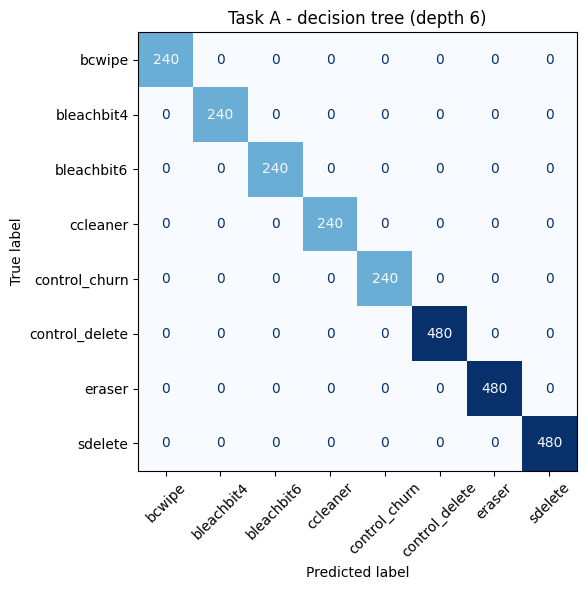

== Task A - random forest: macro-F1 1.000
                precision    recall  f1-score   support

        bcwipe      1.000     1.000     1.000       240
    bleachbit4      1.000     1.000     1.000       240
    bleachbit6      1.000     1.000     1.000       240
      ccleaner      1.000     1.000     1.000       240
 control_churn      1.000     1.000     1.000       240
control_delete      1.000     1.000     1.000       480
        eraser      1.000     1.000     1.000       480
       sdelete      1.000     1.000     1.000       480

      accuracy                          1.000      2640
     macro avg      1.000     1.000     1.000      2640
  weighted avg      1.000     1.000     1.000      2640



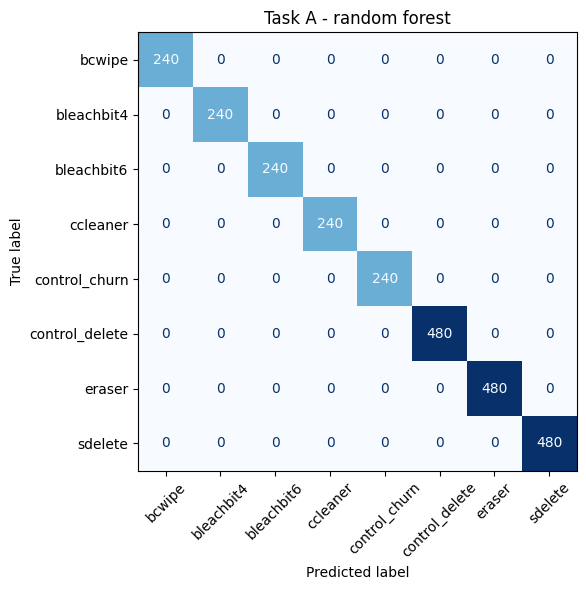

In [23]:
def evaluate(X, y, groups, model, title, show=True):
    pred = cross_val_predict(model, X, y, groups=groups, cv=LeaveOneGroupOut())
    macro = f1_score(y, pred, average="macro")
    if show:
        print(f"== {title}: macro-F1 {macro:.3f}")
        print(classification_report(y, pred, digits=3, zero_division=0))
        fig, ax = plt.subplots(figsize=(7, 6))
        ConfusionMatrixDisplay.from_predictions(y, pred, ax=ax, xticks_rotation=45,
                                                colorbar=False, cmap="Blues")
        ax.set_title(title); plt.tight_layout(); plt.show()
    return macro, pred

# Depth 6: with CCleaner and BCWipe there are 8 per-file classes, and a depth-4
# tree has no room to split BleachBit 6 from 4 or CCleaner from BCWipe (macro-F1
# fell to 0.50 on 72 runs). The fitted tree only uses depth 5.
tree_A = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RNG)
rf_A   = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RNG, n_jobs=-1)

f1_tree_A, _ = evaluate(A[FEATS_A], A["label"], A["config"], tree_A, "Task A - decision tree (depth 6)")
f1_rf_A, _   = evaluate(A[FEATS_A], A["label"], A["config"], rf_A,   "Task A - random forest")

### From model to signature rules

The proposal calls for explicit, portable per-tool rules rather than an opaque
classifier. A shallow decision tree is exactly that: each path is a readable
rule. Fit it on all the data and print it — these are **candidate rules** for
the signature database, to be checked against the literature (e.g. SDelete's 26
alphabetic renames).

|--- n_renames <= 16.50
|   |--- n_renames <= 4.50
|   |   |--- n_overwrite <= 1.00
|   |   |   |--- deleted <= 0.50
|   |   |   |   |--- class: control_churn
|   |   |   |--- deleted >  0.50
|   |   |   |   |--- class: control_delete
|   |   |--- n_overwrite >  1.00
|   |   |   |--- n_basic_info <= 1.00
|   |   |   |   |--- n_renames <= 1.50
|   |   |   |   |   |--- class: bleachbit6
|   |   |   |   |--- n_renames >  1.50
|   |   |   |   |   |--- class: bleachbit4
|   |   |   |--- n_basic_info >  1.00
|   |   |   |   |--- nm_entropy <= 1.95
|   |   |   |   |   |--- class: ccleaner
|   |   |   |   |--- nm_entropy >  1.95
|   |   |   |   |   |--- class: bcwipe
|   |--- n_renames >  4.50
|   |   |--- class: eraser
|--- n_renames >  16.50
|   |--- class: sdelete



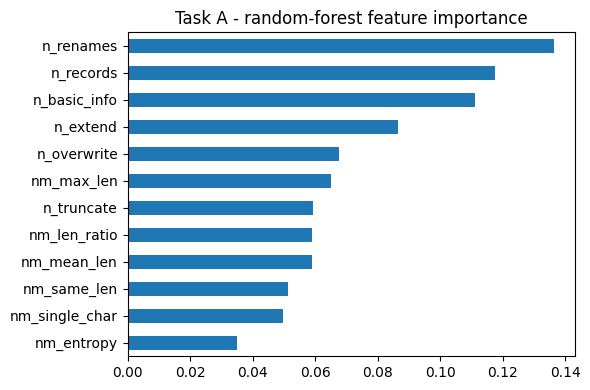

In [24]:
tree_A.fit(A[FEATS_A], A["label"])
print(export_text(tree_A, feature_names=FEATS_A, decimals=2))

rf_A.fit(A[FEATS_A], A["label"])
imp = pd.Series(rf_A.feature_importances_, index=FEATS_A).sort_values()
imp.tail(12).plot.barh(figsize=(6, 4), title="Task A - random-forest feature importance")
plt.tight_layout(); plt.show()

## 6. Task B — run-level features and the Prefetch ablation

One row per run. Journal features summarise *all* activity in the wipe window
(including files the tool creates itself, such as cipher's `EFSTMPWP` folder).
Prefetch features are one column per executable whose Prefetch file appears in
some runs but not in all of them (i.e. not part of the baseline).

The proposal's robustness test is an ablation: how well does attribution work
with the journal alone, with Prefetch alone, and with both?

In [25]:
def run_features(j):
    r = j["reason"].to_numpy()
    # One rename produces two RENAME_NEW_NAME records (the change, then the same
    # flag again with CLOSE). Count only the non-CLOSE one = one per rename.
    renames = j.loc[[flag(x, "RENAME_NEW_NAME") and not flag(x, "CLOSE") for x in r], "name"]
    files = j[["record", "seq"]].drop_duplicates().shape[0]
    stems = renames.str.replace(".", "", regex=False)
    return dict(
        j_records=len(j),
        j_files=files,
        j_creates=sum(flag(x, "FILE_CREATE") for x in r),
        j_deletes=sum(flag(x, "FILE_DELETE") for x in r),
        j_renames=len(renames),
        j_overwrite=sum(flag(x, "DATA_OVERWRITE") for x in r),
        j_extend=sum(flag(x, "DATA_EXTEND") for x in r),
        j_truncate=sum(flag(x, "DATA_TRUNCATION") for x in r),
        # Per touched file, NOT per delete: SDelete's final FILE_DELETE record is
        # only written at a clean shutdown (see section 8), so "per delete"
        # measured the shutdown mode rather than the tool.
        j_renames_per_file=len(renames) / max(1, files),
        j_single_char_names=float(np.mean([len(set(s)) == 1 for s in stems])) if len(stems) else 0.0,
        j_long_names=float((renames.str.len() > 100).mean()) if len(renames) else 0.0,
        j_tilde_names=float(renames.str.startswith("~").mean()) if len(renames) else 0.0,
        j_efstmpwp=int(j["name"].str.upper().eq("EFSTMPWP").any()),
        j_span_s=(j["ts"].max() - j["ts"].min()).total_seconds(),
    )

B = pd.DataFrame({rid: run_features(g) for rid, g in usn.groupby("run_id")}).T
B = B.join(runs[["tool", "config", "shutdown"]])

# Prefetch: executables seen in some runs but not all (all-run ones are baseline noise).
seen = Counter(x for v in prefetch.values() for x in v)
pf_names = sorted(x for x, c in seen.items() if c < len(prefetch))
for exe in pf_names:
    B["pf_" + exe] = [int(exe in prefetch[rid]) for rid in B.index]

# Prefetch from the harness itself or Windows background tasks, not from the
# tool under test. VSSVC.EXE is the Volume Shadow Copy service the agent uses to
# collect Prefetch/Amcache; the others are OS maintenance. They happen to
# correlate with the label in this small dataset, which would be a spurious cue.
PF_NOISE = {"VSSVC.EXE", "COMPATTELRUNNER.EXE", "STOREDESKTOPEXTENSION.EXE",
            "WINDOWSPACKAGEMANAGERSERVER.E", "WINDOWSPACKAGEMANAGERSERVER.EXE"}
# Batch effect: runs 0061-0072 (CCleaner, BCWipe) were collected on 6 Nov, three
# weeks after 0001-0060. Booting the same snapshot later triggered Defender
# signature/engine updates, an Edge update and .NET native-image compiles, so
# these executables appear in all 12 new runs and in none of the old 60. They
# mark the collection date, not the wiper, and would let a model learn
# "new batch => CCleaner or BCWipe". Drop them as well.
PF_BATCH = {"AM_BASE.EXE", "AM_DELTA.EXE", "MPSIGSTUB.EXE", "MPCMDRUN.EXE", "MPRECOVERY.EXE",
            "MSMPENG.EXE", "MPDEFENDERCORESERVICE.EXE", "DEFENDERSESSIONHELPER.EXE",
            "MSCORSVW.EXE", "NGEN.EXE", "NGENTASK.EXE", "DIRECTXDATABASEUPDATER.EXE",
            "TRUSTEDINSTALLER.EXE", "UIEORCHESTRATOR.EXE", "UIEORCHESTRATORSTUB.EXE",
            "UTILITYAPP.EXE", "UPDATEPLATFORM.AMD64FRE.EXE", "SIHCLIENT.EXE",
            "GPSCRIPT.EXE"}
PF_BATCH_PREFIX = ("AM_ENGINE_PATCH", "MICROSOFTEDGE_X64_", "COPILOTUNDOCKEDHOST_")
is_noise = lambda exe: exe in PF_NOISE or exe in PF_BATCH or exe.startswith(PF_BATCH_PREFIX)
B = B.drop(columns=[c for c in B.columns if c.startswith("pf_") and is_noise(c[3:])])

# j_span_s is timing (host speed, and how long until shutdown) - kept in the
# table, not used for training, as in Task A.
FEATS_J  = [c for c in B.columns if c.startswith("j_") and c != "j_span_s"]
FEATS_PF = [c for c in B.columns if c.startswith("pf_")]
print(f"{len(B)} runs, {len(FEATS_J)} journal features, {len(FEATS_PF)} Prefetch features")
print("Prefetch executables used as features:", [c[3:] for c in FEATS_PF])

72 runs, 13 journal features, 21 Prefetch features
Prefetch executables used as features: ['BCRESIDENT.EXE', 'BCUPDT.EXE', 'BCWIPE-SETUP.EXE', 'BCWIPE.EXE', 'BCWIPESVC.EXE', 'BCWIPETM.EXE', 'BLEACHBIT-4.6.0-SETUP.EXE', 'BLEACHBIT-6.0.4-SETUP.EXE', 'BLEACHBIT_CONSOLE.EXE', 'CCLEANER64.EXE', 'CCSETUP.EXE', 'CCUPDATE.EXE', 'CIPHER.EXE', 'ERASER.EXE', 'FC-CACHE.EXE', 'ICACLS.EXE', 'MOFCOMP.EXE', 'RUNONCE.EXE', 'SCHTASKS.EXE', 'SDELETE64.EXE', 'TASKKILL.EXE']


In [26]:
rf_B = RandomForestClassifier(n_estimators=300, random_state=RNG, n_jobs=-1)
ablation = {}
for name, cols in {"journal only": FEATS_J, "Prefetch only": FEATS_PF,
                   "journal + Prefetch": FEATS_J + FEATS_PF}.items():
    ablation[name], _ = evaluate(B[cols].astype(float), B["tool"], B["config"], rf_B,
                                 f"Task B - {name}", show=False)
abl = pd.Series(ablation, name="macro-F1 (leave-one-config-out)").round(3)
abl.to_frame()

,macro-F1 (leave-one-config-out)
journal only,1.000
Prefetch only,0.867
journal + Prefetch,1.000


== Task B - journal + Prefetch: macro-F1 1.000
                precision    recall  f1-score   support

        bcwipe      1.000     1.000     1.000         6
    bleachbit4      1.000     1.000     1.000         6
    bleachbit6      1.000     1.000     1.000         6
      ccleaner      1.000     1.000     1.000         6
        cipher      1.000     1.000     1.000         6
 control_churn      1.000     1.000     1.000         6
control_delete      1.000     1.000     1.000        12
        eraser      1.000     1.000     1.000        12
       sdelete      1.000     1.000     1.000        12

      accuracy                          1.000        72
     macro avg      1.000     1.000     1.000        72
  weighted avg      1.000     1.000     1.000        72



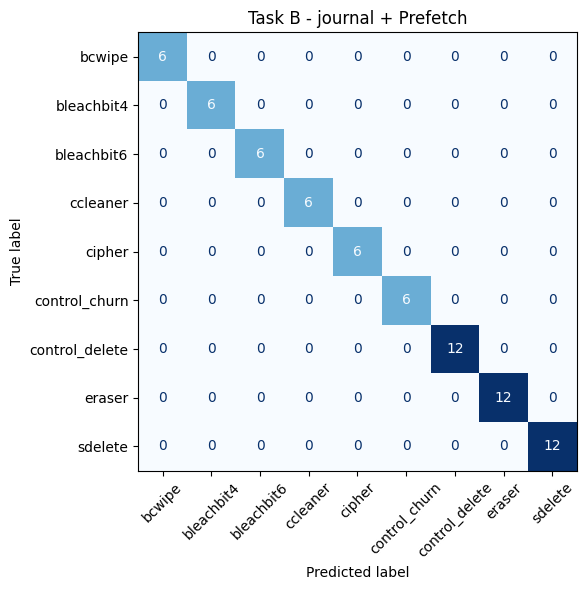

Journal-only run-level rules:

|--- j_renames_per_file <= 0.74
|   |--- j_deletes <= 531.50
|   |   |--- class: control_delete
|   |--- j_deletes >  531.50
|   |   |--- class: cipher
|--- j_renames_per_file >  0.74
|   |--- j_overwrite <= 87.00
|   |   |--- j_renames_per_file <= 14.05
|   |   |   |--- class: control_churn
|   |   |--- j_renames_per_file >  14.05
|   |   |   |--- class: sdelete
|   |--- j_overwrite >  87.00
|   |   |--- j_tilde_names <= 0.00
|   |   |   |--- j_extend <= 197.00
|   |   |   |   |--- j_renames <= 62.00
|   |   |   |   |   |--- j_single_char_names <= 0.45
|   |   |   |   |   |   |--- class: bleachbit6
|   |   |   |   |   |--- j_single_char_names >  0.45
|   |   |   |   |   |   |--- class: ccleaner
|   |   |   |   |--- j_renames >  62.00
|   |   |   |   |   |--- class: bleachbit4
|   |   |   |--- j_extend >  197.00
|   |   |   |   |--- class: bcwipe
|   |   |--- j_tilde_names >  0.00
|   |   |   |--- j_tilde_names <= 0.02
|   |   |   |   |--- class: eraser
|

In [27]:
# Full report for the combined model, and the readable run-level rules.
evaluate(B[FEATS_J + FEATS_PF].astype(float), B["tool"], B["config"], rf_B,
         "Task B - journal + Prefetch")
# No depth cap here: 9 classes do not fit in a depth-4 tree, and a capped tree
# silently drops a class from the printed rules.
tree_B = DecisionTreeClassifier(min_samples_leaf=3, random_state=RNG).fit(B[FEATS_J].astype(float), B["tool"])
missing = set(B["tool"]) - set(tree_B.classes_[np.unique(tree_B.tree_.value.argmax(axis=2)[tree_B.tree_.children_left == -1])])
print("Journal-only run-level rules:" + (f"  (classes with no leaf: {missing})" if missing else "") + "\n")
print(export_text(tree_B, feature_names=FEATS_J, decimals=2))
# NOTE: these thresholds are absolute counts for a 40-file wipe and scale with
# the number of files wiped. The per-file rules from Task A are the portable
# ones to carry into the signature database.

## 7. Save the feature tables

Saved next to the data on Drive so later notebooks (or the WiperTrace rule
engine) can load them without re-parsing.

In [28]:
A.to_csv(OUT_DIR / "task_a_file_features.csv", index=False)
B.to_csv(OUT_DIR / "task_b_run_features.csv")
abl.to_csv(OUT_DIR / "task_b_ablation.csv")
print("saved to", OUT_DIR)

saved to /content/drive/MyDrive/Colab Notebooks/DF/ml_out


## 8. Caveats to carry into the report

* **Small, replayed dataset.** 72 runs, 24 configurations; repeats are near
  duplicates. Report leave-one-configuration-out scores, never random-split ones.
* **Overwrite modes are invisible to the journals.** SDelete `-p 1` vs `-p 3` and
  Eraser Gutmann vs pseudorandom produce identical metadata, so labels are at
  **tool** level. That is a finding, not a modelling failure.
* **Perfect scores describe a clean lab, not the field.** One build per tool,
  one Windows build, one corpus, no background users. Treat 1.0 here as "the
  signatures are internally consistent", and test robustness separately
  (other corpora, a second Windows build, journals that have partly rolled over).
* **Shutdown mode is visible - and explains SDelete's missing deletes.**
  SDelete's last step renames each file to a file-ID name (e.g.
  `000100000000002A6E15C844`) under a different parent directory (MFT record
  29, most likely `$Extend\$Deleted`, where NTFS parks files deleted while a
  handle is still open). The `FILE_DELETE` record is only written when the
  volume is cleanly shut down, ~30 s later. After a hard power cut it never
  appears and the file is left in that directory. So `deleted` / `j_deletes`
  measure the shutdown, not the tool: a rule must not *require* the delete
  record, and a file-ID name under that directory is itself evidence.
* **CCleaner and BCWipe were automated differently.** CCleaner has no
  per-file wipe switch: its custom-file list was set to the 40 targets with
  secure deletion on (1 pass), then `CCleaner64.exe /AUTO` ran. BCWipe ran
  `BCWipe.exe Delete -UD1` per file; the trial allows only one pass. So both
  are one configuration each (times clean/hard shutdown).
* **Similar names, different counts.** CCleaner renames each file once to a
  same-length name of Z's (`ZZZZZZ.ZZZ`), which is also SDelete's *last*
  letter name. The rename count (1 vs ~27) is what separates them.
* **Installer Prefetch names leak the label** (e.g. `BLEACHBIT-6.0.4-SETUP.EXE`,
  `CCSETUP.EXE`, `BCWIPE-SETUP.EXE`).
  They are genuine evidence here, but a real suspect may have renamed the
  installer — the *journal only* ablation row is the conservative number.
* **Two collection batches.** Runs 0061-0072 were collected three weeks after
  0001-0060. The journals are unaffected (same snapshot, same corpus), but
  Windows had updates waiting, so Defender, Edge and .NET executables show up
  in Prefetch for the new runs only. Section 6 drops them (`PF_BATCH`); the
  BCWipe installer's own helpers (`ICACLS`, `SCHTASKS`, `TASKKILL`, `MOFCOMP`)
  are kept as install evidence. The *journal only* row is again the safe one.
* **`$LogFile` features are less stable for BCWipe.** `$LogFile` is a 16 MB
  ring buffer and BCWipe floods it, so what is left depends on when the flood
  stopped. In run 0071 the flood ran about half as long and three times as many
  per-file rename/attribute operations survived, and the `$LogFile`-only model
  called it SDelete (macro-F1 0.985). The journal still classifies it correctly.
* **Not yet used:** `$LogFile` (`evidence/$LogFile.gz`), `$MFT`, and Amcache.
  Adding `$LogFile` operation sequences is the natural next feature block, and
  the ablation table is where its contribution would show.

---
# Part 2 — `$MFT`, `$LogFile` and Amcache

Part 1 used `$UsnJrnl:$J` and Prefetch. Part 2 analyses the three artifact
classes not yet used, then combines everything in one ablation (section 12).

| Section | Artifact | Questions |
|---|---|---|
| 10 | `$MFT` | What does each tool leave in the wiped file's MFT record? Where do SDelete's files go? |
| 11 | `$LogFile` | Which NTFS operations does each tool cause? Does any tool remove the original names? |
| 12 | `$LogFile` (model) | Can the tool be identified from `$LogFile` alone, e.g. if `$UsnJrnl` was deleted? |
| 13 | Amcache | Which tools are recorded? |

In [29]:
# Part 2 needs one extra package (registry parser for Amcache).
if IN_COLAB:
    !pip -q install regipy

import gzip, json, re, struct, warnings, logging
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import f1_score, classification_report

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

def run_info(d):
    m = json.loads((d / "manifest.json").read_text(encoding="utf-8-sig"))
    shutdown = re.search(r"_(clean|hard)_r\d+$", d.name).group(1)
    return m, dict(run_id=d.name, tool=m["tool_id"], mode=m["mode"], shutdown=shutdown,
                   config=f'{m["tool_id"]}|{m["mode"]}|{shutdown}')

RUNS = {d.name: run_info(d) for d in run_dirs}

## 9. Parsers

Both are small, dependency-free readers written for this project. They read
only what the analysis needs.

* **`$MFT`**: fixed 1024-byte `FILE` records, update-sequence fix-up applied.
  Pulls the in-use flag, sequence number, `$STANDARD_INFORMATION` and
  `$FILE_NAME` timestamps, file name and parent, `$DATA` size, and whether an
  `$ATTRIBUTE_LIST` exists. Timestamps are kept as raw FILETIME integers,
  because Eraser sets them to 1601, outside the range pandas can hold.
* **`$LogFile`**: `RCRD` pages (fix-up applied), then every log record. A
  record header is accepted only if its own LSN maps back to the file offset it
  was found at (`LSN × 8 mod log size = offset`), which makes the scan
  self-validating and lets records that cross page boundaries be followed.
  The NTFS client data gives the redo/undo operation codes and their data.

In [30]:
# ---------------- $MFT ----------------
def _fixup(buf, sector=512):
    usa_off, usa_cnt = struct.unpack_from("<HH", buf, 4)
    b = bytearray(buf); usn = b[usa_off:usa_off + 2]
    for k in range(1, usa_cnt):
        end = k * sector - 2
        if end + 2 > len(b): break
        if b[end:end + 2] != usn: return None
        b[end:end + 2] = b[usa_off + 2 * k:usa_off + 2 * k + 2]
    return bytes(b)

def mft_record(mft_bytes, idx):
    raw = mft_bytes[idx * 1024:(idx + 1) * 1024]
    if raw[:4] != b"FILE": return None
    rec = _fixup(raw)
    if rec is None: return None
    seq, _, attr_off, flags, used = struct.unpack_from("<HHHHI", rec, 16)
    out = dict(record=idx, seq=seq, in_use=bool(flags & 1), is_dir=bool(flags & 2),
               name=None, parent=None, si_created=None, si_modified=None, fn_created=None,
               data_size=None, has_attr_list=False)
    off = attr_off
    while off + 16 <= min(used, len(rec)):
        atype, alen = struct.unpack_from("<II", rec, off)
        if atype == 0xFFFFFFFF or alen == 0 or off + alen > len(rec): break
        nonres, nlen = rec[off + 8], rec[off + 9]
        if not nonres:
            clen, coff = struct.unpack_from("<IH", rec, off + 16)
            content = rec[off + coff:off + coff + clen]
        else:
            content = None
        if atype == 0x10 and content and len(content) >= 16:
            out["si_created"], out["si_modified"] = struct.unpack_from("<QQ", content, 0)
        elif atype == 0x20:
            out["has_attr_list"] = True
        elif atype == 0x30 and content and len(content) >= 66 and out["name"] is None:
            parent = struct.unpack_from("<Q", content, 0)[0]
            out["fn_created"] = struct.unpack_from("<Q", content, 8)[0]
            out["parent"] = parent & 0xFFFFFFFFFFFF
            out["name"] = content[66:66 + 2 * content[64]].decode("utf-16le", "replace")
        elif atype == 0x80 and nlen == 0:
            out["data_size"] = struct.unpack_from("<Q", rec, off + 48)[0] if nonres else len(content)
        off += alen
    return out

FT_1970 = 116_444_736_000_000_000
def ft_to_ts(v):
    """FILETIME -> pandas Timestamp, or None for 0 / pre-1970 values (e.g. Eraser's 1601)."""
    return pd.to_datetime((v - FT_1970) // 10, unit="us", utc=True) if v and v > FT_1970 else None

# ---------------- $LogFile ----------------
PAGE, DATA_START = 4096, 0x40
OPS = {0:"Noop",1:"CompensationLogRecord",2:"InitializeFileRecordSegment",3:"DeallocateFileRecordSegment",
 4:"WriteEndOfFileRecordSegment",5:"CreateAttribute",6:"DeleteAttribute",7:"UpdateResidentValue",
 8:"UpdateNonresidentValue",9:"UpdateMappingPairs",10:"DeleteDirtyClusters",11:"SetNewAttributeSizes",
 12:"AddIndexEntryRoot",13:"DeleteIndexEntryRoot",14:"AddIndexEntryAllocation",15:"DeleteIndexEntryAllocation",
 16:"WriteEndOfIndexBuffer",17:"SetIndexEntryVcnRoot",18:"SetIndexEntryVcnAllocation",19:"UpdateFileNameRoot",
 20:"UpdateFileNameAllocation",21:"SetBitsInNonresidentBitMap",22:"ClearBitsInNonresidentBitMap",23:"HotFix",
 24:"EndTopLevelAction",25:"PrepareTransaction",26:"CommitTransaction",27:"ForgetTransaction",
 28:"OpenNonresidentAttribute",29:"OpenAttributeTableDump",30:"AttributeNamesDump",31:"DirtyPageTableDump",
 32:"TransactionTableDump",33:"UpdateRecordDataRoot",34:"UpdateRecordDataAllocation",
 35:"UpdateRelativeDataInIndex",36:"UpdateRelativeDataInIndex2",37:"ZeroEndOfFileRecord"}

def _fix_page(p):
    if p[:4] != b"RCRD": return None
    return _fixup(p)

def logfile_records(path):
    raw = gzip.open(path).read()
    size = len(raw)
    pages = {off: fx for off in range(0, size, PAGE)
             if (fx := _fix_page(raw[off:off + PAGE])) is not None}

    def span(off, n):
        out = bytearray()
        while len(out) < n:
            pg = off - off % PAGE
            if pg not in pages: return None
            take = min(n - len(out), PAGE - off % PAGE)
            out += pages[pg][off % PAGE:off % PAGE + take]
            off = pg + PAGE
            if off >= size: off = 2 * PAGE          # wrap past the two restart pages
            off += DATA_START
        return bytes(out)

    seen, recs = set(), []
    for pg, p in sorted(pages.items()):
        o = DATA_START
        while o + 0x30 <= PAGE:
            lsn = struct.unpack_from("<Q", p, o)[0]
            if lsn and (lsn * 8) % size == pg + o and lsn not in seen:
                clen = struct.unpack_from("<I", p, o + 0x18)[0]
                rtype = struct.unpack_from("<I", p, o + 0x20)[0]
                if rtype in (1, 2) and 0 < clen < 0x10000:
                    data = span(pg + o + 0x30, clen)
                    if data is not None:
                        seen.add(lsn)
                        r = dict(lsn=lsn, type=rtype, redo="", undo="", redo_data=b"", undo_data=b"")
                        if rtype == 1 and clen >= 0x20:
                            redo, undo, ro, rl, uo, ul = struct.unpack_from("<6H", data, 0)
                            r.update(redo=OPS.get(redo, "Other"), undo=OPS.get(undo, "Other"),
                                     redo_data=data[ro:ro + rl], undo_data=data[uo:uo + ul])
                        recs.append(r)
                        o += (0x30 + clen + 7) & ~7
                        continue
            o += 8
    return recs
print("parsers ready")

parsers ready


## 10. `$MFT`: what each tool leaves in the wiped file's record

For each of the 40 target files per run, look up its MFT record *after* the
wipe (the cold image) and compare with the ground truth captured before it.

In [31]:
rows = []
for run_id, (m, info) in RUNS.items():
    mft = gzip.open(run_dirs[0].parent / run_id / "evidence" / "$MFT.gz").read()
    # Sanity check once: record 29 should be $Extend\$Deleted (parent 11 = $Extend).
    if not rows:
        r29 = mft_record(mft, 29); print("record 29 =", r29["name"], "| parent record", r29["parent"])
    for t in m["targets"]:
        r = mft_record(mft, t["mft_record"]) or {}
        rows.append(dict(**info, orig_name=t["name"], orig_size=t["size"],
                         seq_before=t["sequence"], seq_after=r.get("seq"),
                         in_use=r.get("in_use"), name=r.get("name"), parent=r.get("parent"),
                         data_size=r.get("data_size"), has_attr_list=r.get("has_attr_list"),
                         si_created=r.get("si_created"), fn_created=r.get("fn_created")))
M = pd.DataFrame(rows)
M["name_len"] = M["name"].str.len()
M["ts_1601"] = M["si_created"].fillna(FT_1970 + 1).lt(FT_1970) & M["fn_created"].fillna(FT_1970 + 1).lt(FT_1970)

flags = pd.DataFrame({
    "tool": M["tool"], "shutdown": M["shutdown"],
    "record_still_in_use": M["in_use"].astype(float),
    "original_name_left":  (M["name"] == M["orig_name"]).astype(float),
    "in_$Extend\\$Deleted": (M["parent"] == 29).astype(float),
    "size_zeroed":         (M["data_size"] == 0).astype(float),
    "size_unchanged":      (M["data_size"] == M["orig_size"]).astype(float),
    "has_$ATTRIBUTE_LIST": M["has_attr_list"].astype(float),
    "timestamps_1601":     M["ts_1601"].astype(float),
})
mft_summary = flags.groupby(["tool", "shutdown"]).mean().round(2)
mft_summary["typical_name_len"] = M.groupby(["tool", "shutdown"])["name_len"].median()
mft_summary

record 29 = $Deleted | parent record 11


record_still_in_use  original_name_left  in_$Extend\$Deleted  size_zeroed  size_unchanged  has_$ATTRIBUTE_LIST  timestamps_1601  typical_name_len
tool           shutdown                                                                                                                                                   
bcwipe         clean                    0.02                0.00                 0.00         0.98            0.00                 0.00              0.0              12.0
               hard                     0.02                0.00                 0.00         0.98            0.00                 0.00              0.0              12.0
bleachbit4     clean                    0.00                0.00                 0.00         0.02            0.00                 0.98              0.0               1.0
               hard                     0.00                0.00                 0.00         0.02            0.00                 0.98              0.0               1.0
bleachbit6     clean                    0.00                0.00                 0.00         1.00            0.00                 0.00              0.0              10.0
               hard                     0.00                0.00                 0.00         1.00            0.00                 0.00              0.0              10.0
ccleaner       clean                    0.00                0.00                 0.02         0.00            0.05                 0.00              0.0              10.0
               hard                     0.05                0.00                 0.05         0.00            0.05                 0.00              0.0              10.0
cipher         clean                    0.02                0.88                 0.00         0.08            0.88                 0.00              0.0              10.0
               hard                     0.02                0.88                 0.00         0.08            0.88                 0.00              0.0              10.0
control_churn  clean                    1.00                1.00                 0.00         0.00            1.00                 0.00              0.0              10.0
               hard                     1.00                1.00                 0.00         0.00            1.00                 0.00              0.0              10.0
control_delete clean                    0.00                0.50                 0.00         0.00            1.00                 0.00              0.0              10.5
               hard                     0.00                0.50                 0.00         0.00            1.00                 0.00              0.0              10.5
eraser         clean                    0.00                0.00                 0.00         1.00            0.00                 0.00              1.0              10.0
               hard                     0.00                0.00                 0.00         1.00            0.00                 0.00              1.0              10.0
sdelete        clean                    0.00                0.00                 0.94         0.00            1.00                 0.00              0.0              24.0
               hard                     0.99                0.00                 0.99         0.00            1.00                 0.00              0.0              24.0

In [32]:
# One typical residual record per tool: take records whose parent folder is the
# most common one for that tool, which skips the few records already re-used
# by an unrelated file (e.g. cipher's own EFSTMPWP folder).
ex = M[M["name"].notna()]
usual_parent = ex.groupby("tool")["parent"].agg(lambda s: s.mode().iat[0])
ex[ex["parent"] == ex["tool"].map(usual_parent)].groupby("tool").head(1)[
    ["tool", "orig_name", "name", "parent", "data_size", "has_attr_list", "ts_1601"]]

,tool,orig_name,name,parent,data_size,has_attr_list,ts_1601
0,sdelete,001000.ppt,000100000000002A6E15C844,29.0,983040.0,False,False
485,cipher,001005.ppt,001005.ppt,36.0,70656.0,False,False
720,bleachbit6,001000.ppt,4)3#0_=+t&,36.0,0.0,False,False
961,bleachbit4,001001.ppt,o,36.0,NaN,True,False
1200,eraser,001000.ppt,VcFIxlywNf,36.0,0.0,False,True
1680,control_delete,001000.ppt,001000.ppt,36.0,983040.0,False,False
2160,control_churn,001000.ppt,001000.ppt,36.0,983040.0,False,False
2400,ccleaner,001000.ppt,ZZZZZZ.ZZZ,36.0,983040.0,False,False
2642,bcwipe,001002.ppt,poqiowpb.qvu,42.0,0.0,False,False


**Reading the table**

* **SDelete**: the record keeps the **original size**; the name becomes a
  24-character file-ID name in `$Extend\$Deleted` (record 29). After a hard
  shutdown the record is **still in use** there: the file was never finally
  deleted (see section 8).
* **BleachBit 6.0.4**: size zeroed, same-length random name, timestamps kept.
* **BleachBit 4.6.0**: one-character final name, and an **`$ATTRIBUTE_LIST`**
  in a deleted record. Its ~226-character intermediate name overflowed the
  1 KB record and forced NTFS to move attributes into an extension record
  (which is also why `$DATA`, and so the size, is not in the base record).
* **Eraser**: size zeroed and **every `$STANDARD_INFORMATION` and `$FILE_NAME`
  timestamp set to 1601-01-01**, a very strong single-record signature.
* **cipher / ordinary delete**: original name and size left intact; records
  are only marked free. (A few cipher records are re-used by its fill files.)

## 11. `$LogFile`: operation profile and surviving names

The `$LogFile` restarts from the same point in every run (the snapshot), so
almost all of it is activity from that run. Counts are divided by the 40
wiped files, to give operations per file.

In [33]:
op_rows, name_rows, LOG = [], [], {}
for run_id, (m, info) in RUNS.items():
    recs = logfile_records(run_dirs[0].parent / run_id / "evidence" / "$LogFile.gz")
    LOG[run_id] = recs
    ops = Counter(r["redo"] for r in recs if r["type"] == 1)
    ops["Checkpoint"] = sum(r["type"] == 2 for r in recs)
    op_rows.append(dict(**info, n_records=len(recs), **ops))
    blob = b"".join(r["undo_data"] + r["redo_data"] for r in recs)
    name_rows.append(dict(**info,
        original_names_in_log=sum(t["name"].encode("utf-16le") in blob for t in m["targets"]),
        sdelete_letter_names=len(set(re.findall(rb"(?:([A-Z])\x00)\1\x00\1\x00\1\x00\1\x00\1\x00\.\x00\1\x00\1\x00\1\x00", blob)))))
L = pd.DataFrame(op_rows).fillna(0)
N = pd.DataFrame(name_rows)
OP_COLS = [c for c in L.columns if c not in ("run_id", "tool", "mode", "shutdown", "config", "n_records")]
per_file = (L.groupby("tool")[OP_COLS].mean() / 40).round(1)
per_file = per_file.loc[:, per_file.max() >= 0.5]
per_file.T.sort_values("sdelete", ascending=False)

tool,bcwipe,bleachbit4,bleachbit6,ccleaner,cipher,control_churn,control_delete,eraser,sdelete
SetNewAttributeSizes,657.8,25.4,18.9,19.1,569.6,12.2,11.3,89.4,168.2
UpdateNonresidentValue,98.1,11.7,8.5,9.1,25.5,6.1,5.7,42.7,84.1
ForgetTransaction,1022.9,25.7,13.6,14.2,959.6,7.4,8.9,59.4,83.7
UpdateResidentValue,72.4,25.6,8.0,8.4,5.1,6.3,7.4,37.9,57.7
UpdateFileNameAllocation,63.2,12.1,6.1,6.1,1.2,5.0,3.0,28.1,55.0
DeleteIndexEntryAllocation,32.5,3.0,2.0,2.0,25.5,2.0,2.0,8.1,27.5
DeleteAttribute,31.1,4.0,1.0,1.1,0.4,2.0,0.5,7.0,27.0
CreateAttribute,31.2,7.1,1.0,1.1,0.4,2.0,0.6,7.0,27.0
AddIndexEntryAllocation,33.7,2.1,1.0,1.0,1.2,2.0,1.1,7.0,26.8
Noop,144.9,6.6,3.0,1.1,0.4,1.0,0.6,6.6,24.6


In [34]:
N.groupby(["tool", "shutdown"])[["original_names_in_log", "sdelete_letter_names"]].mean()

original_names_in_log  sdelete_letter_names
tool           shutdown                                             
bcwipe         clean                  1.000000                   0.0
               hard                   1.333333                   0.0
bleachbit4     clean                 40.000000                   0.0
               hard                  40.000000                   0.0
bleachbit6     clean                 40.000000                   0.0
               hard                  40.000000                   0.0
ccleaner       clean                 40.000000                   1.0
               hard                  40.000000                   1.0
cipher         clean                 40.000000                   0.0
               hard                  40.000000                   0.0
control_churn  clean                 40.000000                   0.0
               hard                  40.000000                   0.0
control_delete clean                 40.000000                   0.0
               hard                  40.000000                   0.0
eraser         clean                 40.000000                   0.0
               hard                  40.000000                   0.0
sdelete        clean                 40.000000                  26.0
               hard                  40.000000                  26.0

**Reading the tables**

* **Original names survive in `$LogFile` for every tool except BCWipe:
  40 of 40 in every other run.** The undo data of the index-entry deletions
  holds the original `$FILE_NAME`, consistent with Zareen et al.'s finding
  that many tools do not wipe `$LogFile` properly.
* **BCWipe is the exception: it wipes `$LogFile`.** It repeatedly creates a
  `LOGFILEWIPER` temp file until the whole 16 MB log has been overwritten
  (about 4,000 pages and ~127,000 records per run), leaving about 1 of the
  40 original names. The flooded log is itself a strong BCWipe signature,
  and `$UsnJrnl` still records its renames.
* **SDelete's full A–Z rename chain is visible in `$LogFile` too** (all 26
  letter names), so its signature survives even if `$UsnJrnl` is gone.
* Per wiped file: SDelete ~27 `CreateAttribute`/`DeleteAttribute` pairs (one
  per rename); Eraser ~7 plus many `UpdateResidentValue` (timestamp resets);
  BleachBit 4 a `WriteEndOfFileRecordSegment` + `InitializeFileRecordSegment`
  (the extension record from section 10); cipher hundreds of
  `Set/ClearBitsInNonresidentBitMap` and `UpdateMappingPairs`, from
  allocating and freeing its free-space fill files.

## 12. Identifying the tool from `$LogFile`, and the full ablation

One row per run, with `$LogFile` operations per wiped file as features. It is
evaluated exactly like Task B in section 6 (leave one configuration
out), then combined with the saved journal (`j_*`) and Prefetch (`pf_*`)
features. The interesting rows are the ones **without** the journal: they
model a suspect who deleted `$UsnJrnl`, or a journal that has rolled over.

In [35]:
LF = L.set_index("run_id")[OP_COLS] / 40
LF = LF.loc[:, (LF > 0).any()].add_prefix("lf_")
FEATS_LF = list(LF.columns)

b_path = OUT_DIR / "task_b_run_features.csv"
if b_path.exists():
    B = pd.read_csv(b_path, index_col=0).join(LF)
else:
    print("task_b_run_features.csv not found - run sections 1-7 first; using $LogFile only")
    B = LF.join(L.set_index("run_id")[["tool", "config"]])
FEATS_J  = [c for c in B.columns if c.startswith("j_") and c != "j_span_s"]
FEATS_PF = [c for c in B.columns if c.startswith("pf_")]

rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)
def loco_f1(cols):
    pred = cross_val_predict(rf, B[cols].astype(float), B["tool"], groups=B["config"], cv=LeaveOneGroupOut())
    return f1_score(B["tool"], pred, average="macro"), pred

sets = {"$LogFile only": FEATS_LF}
if FEATS_J:
    sets.update({"journal only": FEATS_J, "Prefetch only": FEATS_PF,
                 "$LogFile + Prefetch  (journal gone)": FEATS_LF + FEATS_PF,
                 "journal + $LogFile": FEATS_J + FEATS_LF,
                 "all three": FEATS_J + FEATS_LF + FEATS_PF})
ablation = pd.Series({k: round(loco_f1(v)[0], 3) for k, v in sets.items()},
                     name="macro-F1 (leave-one-config-out)")
ablation.to_frame()

,macro-F1 (leave-one-config-out)
$LogFile only,0.985
journal only,1.000
Prefetch only,0.867
$LogFile + Prefetch (journal gone),0.985
journal + $LogFile,0.985
all three,0.985


In [36]:
f1, pred = loco_f1(FEATS_LF)
print(classification_report(B["tool"], pred, digits=3, zero_division=0))

                precision    recall  f1-score   support

        bcwipe      1.000     0.833     0.909         6
    bleachbit4      1.000     1.000     1.000         6
    bleachbit6      1.000     1.000     1.000         6
      ccleaner      1.000     1.000     1.000         6
        cipher      1.000     1.000     1.000         6
 control_churn      1.000     1.000     1.000         6
control_delete      1.000     1.000     1.000        12
        eraser      1.000     1.000     1.000        12
       sdelete      0.923     1.000     0.960        12

      accuracy                          0.986        72
     macro avg      0.991     0.981     0.985        72
  weighted avg      0.987     0.986     0.986        72



## 13. Amcache

Amcache (`C:\Windows\appcompat\Programs\Amcache.hve`) is parsed with `regipy`,
searching every key name and value for the tool names.

In [37]:
from regipy.registry import RegistryHive
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
TOOL_RE = re.compile(r"sdelete|bleachbit|eraser|cipher\.exe|ccleaner|bcwipe", re.I)
am_rows = []
for run_id, (m, info) in RUNS.items():
    hive = next((run_dirs[0].parent / run_id / "artifacts").rglob("Amcache.hve"), None)
    hits, n_keys = [], 0
    if hive:
        for k in RegistryHive(str(hive)).recurse_subkeys(as_json=False):
            n_keys += 1
            text = k.path + " " + " ".join(f"{v.name}={v.value}" for v in (k.values or []))
            if TOOL_RE.search(text):
                hits.append(k.path.split("\\")[-1])
    am_rows.append(dict(**info, amcache_keys=n_keys, tool_entries=len(hits), example=hits[0] if hits else ""))
AM = pd.DataFrame(am_rows)
AM.groupby("tool").agg(runs=("run_id", "size"), runs_with_entry=("tool_entries", lambda s: (s > 0).sum()),
                      hive_keys=("amcache_keys", "median"), example=("example", "max"))

,runs,runs_with_entry,hive_keys,example
tool,,,,
bcwipe,6,0,199.0,
bleachbit4,6,0,199.0,
bleachbit6,6,0,199.0,
ccleaner,6,0,199.0,
cipher,6,0,199.0,
control_churn,6,0,199.0,
control_delete,12,0,199.0,
eraser,12,12,200.0,eraser.exe|45c5c950eb6fa1ac
sdelete,12,0,199.0,


**Reading the table.** Only Eraser appears, as a single
`InventoryApplicationFile\eraser.exe|…` key whose `FileId` (the SHA-1) is
still empty: a stub created when its MSI installer ran. The hive holds only
~200 keys in every run. Amcache is filled in mainly by a scheduled
inventory task rather than at the moment a program runs, and each run lasts
only a few minutes, so the portable tools and the BleachBit, CCleaner and BCWipe installs
never reach it. On a real machine examined days later these entries would be
expected; here, Amcache is a weak signal and that is a limitation of short
runs, not proof the tools leave no trace.

## 14. Save

In [38]:
M.to_csv(OUT_DIR / "mft_target_residue.csv", index=False)
mft_summary.to_csv(OUT_DIR / "mft_summary.csv")
L.to_csv(OUT_DIR / "logfile_ops_per_run.csv", index=False)
N.to_csv(OUT_DIR / "logfile_name_survival.csv", index=False)
AM.to_csv(OUT_DIR / "amcache_entries.csv", index=False)
ablation.to_csv(OUT_DIR / "ablation_all_artifacts.csv")
print("saved to", OUT_DIR)

saved to /content/drive/MyDrive/Colab Notebooks/DF/ml_out
